*CS 545 final project · Ian Fisk, Ryan Baldwin · draft of the "Time series basics" section of `finalreport.ipynb`*

# Time series basics

Everything in this course so far has been about sequences of *words*. A sentence goes into BERT as a list of token ids, each id looks up a learned embedding, and attention mixes those embeddings into context-aware representations.

PatchTST applies the same transformer to a different kind of sequence: measurements taken over time. Before we can say what changes and why, we need to be precise about what that data looks like. This section answers three questions:

1. What is a time series, and what shape does it have as an array?
2. What structure (trend, seasons, noise) makes it predictable at all?
3. How do we turn one long series into training examples, and what exactly does a forecaster predict?

This first draft covers question 1.

In [1]:
# render figures as crisp vector graphics (SVG) in the notebook
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

import sys
import warnings
sys.path.append("..")          # src/, where the shared data loader lives

# NumPy 2.5 warns inside pandas' date arithmetic; it is not about our code.
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch, Rectangle

from ltsf_data import load

## What is a time series?

A **time series** is a sequence of measurements taken at evenly spaced moments: one reading per hour, per 10 minutes, per day. When several quantities are measured on the same clock, we have a **multivariate** time series. Each quantity is called a **channel** (the papers also say *variate*).

Our running example is the CSU weather station in Fort Collins, which records 10 channels (temperature, humidity, wind, pressure, solar radiation, ...) once an hour. Loaded with our data loader, it is simply a 2-D array: one row per hour, one column per channel.

In [2]:
ts = load("csu_weather")
print(ts)
print("values array shape:", ts.values.shape, " (n_steps, M)")
ts.df.head()

TimeSeries('csu_weather', 52608 steps x M=10 channels, every h, 2020-01-01 00:00:00 -> 2025-12-31 23:00:00)
values array shape: (52608, 10)  (n_steps, M)


,Temp,RH,DewPt,Wind,WindDir,Gust,GustDir,Press,Solar,Prec
date,,,,,,,,,,
2020-01-01 00:00:00,28.900000,62.500000,17.700001,1.6,85.0,7.1,294.0,24.731001,0.0,0.0
2020-01-01 01:00:00,28.200001,61.599998,16.700001,2.2,319.0,10.1,246.0,24.705000,0.0,0.0
2020-01-01 02:00:00,28.200001,58.000000,15.300000,2.2,331.0,7.0,268.0,24.673000,0.0,0.0
2020-01-01 03:00:00,26.200001,63.099998,15.400000,2.2,236.0,6.6,246.0,24.652000,0.0,0.0
2020-01-01 04:00:00,24.700001,67.000000,15.300000,1.4,355.0,5.9,289.0,24.625000,0.0,0.0


Two ways of looking at that array, side by side. On the left, three of the channels plotted against time for one week in June 2023. On the right, the same numbers as rows of the table.

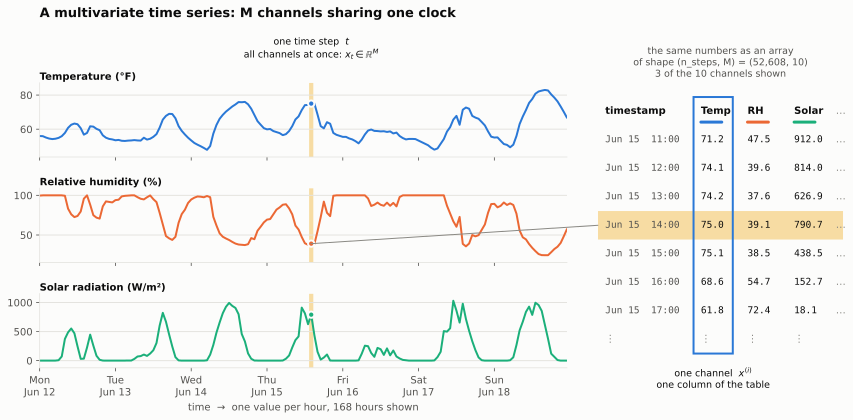

In [3]:
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
SURFACE = "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]      # categorical slots 1-3
HILITE = "#eda100"                              # time-step highlight band

plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
})

plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
})

df = ts.df
start = pd.Timestamp("2023-06-12 00:00")
week = df.loc[start: start + pd.Timedelta(hours=167)]
t_star = pd.Timestamp("2023-06-15 14:00")          # the one time step we highlight

channels = [("Temp", "Temperature", "°F"), ("RH", "Relative humidity", "%"),
            ("Solar", "Solar radiation", "W/m²")]

fig = plt.figure(figsize=(12, 6.0))
gs = fig.add_gridspec(3, 2, width_ratios=[2.15, 1], wspace=0.08, hspace=0.42,
                      left=0.06, right=0.99, top=0.80, bottom=0.14)
axes = [fig.add_subplot(gs[i, 0]) for i in range(3)]

for ax, (col, label, unit), color in zip(axes, channels, SERIES):
    ax.plot(week.index, week[col], color=color, lw=2, solid_capstyle="round")
    ax.axvspan(t_star - pd.Timedelta(minutes=40), t_star + pd.Timedelta(minutes=40),
               color=HILITE, alpha=0.35, lw=0)
    ax.scatter([t_star], [week.loc[t_star, col]], s=40, color=color,
               edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.set_title(f"{label} ({unit})", loc="left", color=INK, fontsize=10,
                 fontweight="bold", pad=3)
    ax.grid(axis="y", color=GRID, lw=1)
    ax.set_xlim(week.index[0], week.index[-1])
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.margins(y=0.12)
    if ax is not axes[-1]:
        ax.tick_params(labelbottom=False)

axes[-1].xaxis.set_major_locator(matplotlib.dates.DayLocator())
axes[-1].xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%a\n%b %d"))
axes[-1].set_xlabel("time  →  one value per hour, 168 hours shown", color=INK2)

# The time-step label above the top panel.
axes[0].annotate("one time step  $t$\nall channels at once: $x_t \\in \\mathbb{R}^M$",
                 xy=(matplotlib.dates.date2num(t_star), axes[0].get_ylim()[1]), xycoords="data",
                 xytext=(0, 22), textcoords="offset points",
                 ha="center", va="bottom", color=INK, fontsize=9.5,
                 annotation_clip=False)

# ---- the same numbers as a table ---------------------------------------------
tax = fig.add_subplot(gs[:, 1])
tax.set_axis_off(); tax.set_xlim(0, 1); tax.set_ylim(0, 1); tax.autoscale(False)
rows = df.loc[t_star - pd.Timedelta(hours=3): t_star + pd.Timedelta(hours=3)]
cols = ["Temp", "RH", "Solar"]
n_rows = len(rows) + 2                         # header + "…" row
row_h = 1.0 / (n_rows + 1)
col_x = [0.03, 0.42, 0.61, 0.80, 0.97]          # time, 3 channels, "…"

def cell_y(i):  # top of table = row 0
    return 1 - (i + 1) * row_h

tax.text(col_x[0], cell_y(0), "timestamp", fontweight="bold", color=INK, va="center")
for j, c in enumerate(cols):
    tax.text(col_x[j + 1], cell_y(0), c, ha="left", fontweight="bold", color=INK, va="center")
    tax.plot([col_x[j + 1], col_x[j + 1] + 0.085], [cell_y(0) - row_h * 0.38] * 2, color=SERIES[j],
             lw=3, solid_capstyle="round", transform=tax.transAxes)
tax.text(col_x[4], cell_y(0), "…", color=MUTED, va="center")

for i, (stamp, r) in enumerate(rows.iterrows(), start=1):
    y = cell_y(i)
    if stamp == t_star:
        tax.add_patch(Rectangle((0, y - row_h / 2), 1, row_h, color=HILITE, alpha=0.35,
                                lw=0, transform=tax.transAxes))
        hl_row_y = y
    tax.text(col_x[0], y, stamp.strftime("%b %d  %H:%M"), color=INK2, va="center",
             family="monospace", fontsize=9.5)
    for j, c in enumerate(cols):
        tax.text(col_x[j + 1], y, f"{r[c]:.1f}", color=INK, va="center",
                 family="monospace", fontsize=9.5)
    tax.text(col_x[4], y, "…", color=MUTED, va="center")
tax.text(col_x[0], cell_y(n_rows - 1), "⋮", color=MUTED, va="center")
for j in range(3):
    tax.text(col_x[j + 1], cell_y(n_rows - 1), "⋮", color=MUTED, va="center")

# Column highlight: one channel = one univariate series.
tax.add_patch(Rectangle((col_x[1] - 0.03, cell_y(n_rows - 1) - row_h / 2), 0.16,
                        (n_rows - 1) * row_h + row_h * 1.0, fill=False,
                        edgecolor=SERIES[0], lw=2, transform=tax.transAxes))
tax.text(col_x[1] + 0.05, cell_y(n_rows - 1) - row_h * 0.95,
         "one channel  $x^{(i)}$\none column of the table", ha="center", va="top",
         color=INK, fontsize=9.5)
tax.text(0.5, 1.01, "the same numbers as an array\nof shape (n_steps, M) = (52,608, 10)\n3 of the 10 channels shown",
         ha="center", va="bottom", transform=tax.transAxes, color=INK2, fontsize=9.5)

# Connector from the highlighted row back to the highlighted moment in the plot.
con = ConnectionPatch(xyA=(0, hl_row_y), coordsA=tax.transAxes,
                      xyB=(matplotlib.dates.date2num(t_star), float(week.loc[t_star, "RH"])), coordsB=axes[1].transData,
                      color=MUTED, lw=1, arrowstyle="-", linestyle="-")
fig.add_artist(con)

fig.suptitle("A multivariate time series: M channels sharing one clock",
             x=0.06, y=0.975, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.show()

### Reading the figure

- **A row is one moment.** The highlighted row is 2pm on June 15: the value of every channel at that hour. In the papers' notation it is a vector $x_t \in \mathbb{R}^M$, where $M$ is the number of channels.
- **A column is one channel over time.** The boxed column is the temperature series by itself, a *univariate* time series $x^{(i)}$. PatchTST's channel independence, which we meet later, treats each column as a separate input.
- **The channels share a clock but not a unit.** Temperature is in °F, humidity in %, solar radiation in W/m². Their scales differ by a factor of 10 or more, which is why each channel is normalized separately before it goes into a model.

The plot also shows the kind of structure forecasting depends on:

- Solar radiation rises and falls once every 24 hours: a **daily season**, 24 steps long at hourly sampling.
- Temperature follows the sun with a lag. In the table, solar radiation is highest by 11am but temperature keeps rising until 3pm.
- Humidity moves opposite to temperature: it drops in the warm afternoons and climbs back to 100% at night.

### How this differs from text

A sentence and a time series are both sequences, but they differ in ways that matter for a transformer:

| | Text (BERT, GPT) | Time series |
|---|---|---|
| One element | a token id from a fixed vocabulary | a vector of $M$ real numbers |
| Meaning of one element | a word means something on its own | 75.0°F says almost nothing without its neighbours |
| How elements enter the model | embedding lookup table | a learned linear projection of real values |
| Typical length | hundreds of tokens | thousands of time steps (52,608 here) |

The second row is the important one. A single time step carries very little information. The pattern only appears across many neighbouring steps, and that observation is what motivates PatchTST's *patches*.

## Coming next

- **Trend, seasons and noise:** the same channel at several zoom levels (year, week, day), and an autocorrelation plot that measures the season lengths.
- **From one series to training examples:** sliding a look-back window of length $L$ and a horizon of length $T$ along the series, and the array shapes that produces, $(n\_steps, M) \rightarrow (N, M, L)$.
- **Predicting the whole horizon at once vs. step by step:** why LTSF models output all $T$ future values in one shot instead of generating them one at a time like an LLM.